In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Set visualization style
sns.set_theme(style="whitegrid")

# Set graph size
plt.rcParams['figure.figsize'] = (10, 5)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from google.colab import files
import io

uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully!")

Saving raw_sales_dataset.csv to raw_sales_dataset (1).csv
Dataset loaded successfully!


In [3]:
# Display first 10 rows

print("FIRST 10 ROWS")
display(df.head(10))

# Display dataset dimensions
print("\nDATASET SHAPE")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Display column names
print("\nCOLUMN NAMES")
print(df.columns.tolist())

# Display data types
print("\nDATA TYPES")
print(df.dtypes)

FIRST 10 ROWS


,Order_ID,Date,Customer_Age,Gender,Product_Category,Quantity,Unit_Price,Payment_Method,City
0,1001,2025-01-01,56.0,Male,Clothing,6,760.0,Card,Bangalore
1,1002,2025-01-02,46.0,Female,Clothing,7,2735.0,Cash,NaN
2,1003,2025-01-03,32.0,Female,Clothing,3,2429.0,Cash,Bangalore
3,1004,2025-01-04,60.0,Female,Clothing,7,4054.0,Cash,Mumbai
4,1005,2025-01-05,25.0,Male,Sports,8,2550.0,Online,Bangalore
5,1006,2025-01-06,NaN,Male,Groceries,6,1232.0,UPI,Delhi
6,1007,2025-01-07,56.0,Male,Electronics,9,799.0,Online,Bangalore
7,1008,2025-01-08,36.0,Male,Furniture,6,2138.0,Card,Mumbai
8,1009,2025-01-09,40.0,Male,Sports,9,4747.0,Card,Mumbai
9,1010,2025-01-10,28.0,Male,Electronics,4,4600.0,Card,Mumbai



DATASET SHAPE
Rows: 1010
Columns: 9

COLUMN NAMES
['Order_ID', 'Date', 'Customer_Age', 'Gender', 'Product_Category', 'Quantity', 'Unit_Price', 'Payment_Method', 'City']

DATA TYPES
Order_ID              int64
Date                 object
Customer_Age        float64
Gender               object
Product_Category     object
Quantity              int64
Unit_Price          float64
Payment_Method       object
City                 object
dtype: object


In [4]:
# Dataset information
print("DATASET INFORMATION")
df.info()

# Statistical summary
print("\nSTATISTICAL SUMMARY")
display(df.describe(include='all'))

# Missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# Duplicate records
print("\nDUPLICATE RECORDS")
print(df.duplicated().sum())

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1010 entries, 0 to 1009
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          1010 non-null   int64  
 1   Date              1010 non-null   object 
 2   Customer_Age      989 non-null    float64
 3   Gender            990 non-null    object 
 4   Product_Category  990 non-null    object 
 5   Quantity          1010 non-null   int64  
 6   Unit_Price        990 non-null    float64
 7   Payment_Method    1010 non-null   object 
 8   City              989 non-null    object 
dtypes: float64(2), int64(2), object(5)
memory usage: 71.1+ KB

STATISTICAL SUMMARY


,Order_ID,Date,Customer_Age,Gender,Product_Category,Quantity,Unit_Price,Payment_Method,City
count,1010.000000,1010,989.000000,990,990,1010.000000,990.000000,1010,989
unique,NaN,1000,NaN,2,5,NaN,NaN,4,5
top,NaN,2025-01-01,NaN,Male,Groceries,NaN,NaN,Online,Chennai
freq,NaN,2,NaN,523,221,NaN,NaN,267,204
mean,1495.599010,NaN,41.129424,NaN,NaN,5.113861,2652.945455,NaN,NaN
std,291.537945,NaN,13.921390,NaN,NaN,3.960897,2055.585636,NaN,NaN
min,1001.000000,NaN,18.000000,NaN,NaN,1.000000,102.000000,NaN,NaN
25%,1243.250000,NaN,29.000000,NaN,NaN,3.000000,1390.000000,NaN,NaN
50%,1495.500000,NaN,42.000000,NaN,NaN,5.000000,2717.500000,NaN,NaN
75%,1747.750000,NaN,52.000000,NaN,NaN,7.000000,3745.000000,NaN,NaN



MISSING VALUES
Order_ID             0
Date                 0
Customer_Age        21
Gender              20
Product_Category    20
Quantity             0
Unit_Price          20
Payment_Method       0
City                21
dtype: int64

DUPLICATE RECORDS
10


In [5]:
# Count missing values in each column

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

# Calculate missing percentage
missing_percentage = (df.isnull().mean() * 100).round(2)

# Create missing values report
missing_report = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

display(missing_report)

Missing Values in Each Column:
Order_ID             0
Date                 0
Customer_Age        21
Gender              20
Product_Category    20
Quantity             0
Unit_Price          20
Payment_Method       0
City                21
dtype: int64


,Missing Values,Missing Percentage
Order_ID,0,0.00
Date,0,0.00
Customer_Age,21,2.08
Gender,20,1.98
Product_Category,20,1.98
Quantity,0,0.00
Unit_Price,20,1.98
Payment_Method,0,0.00
City,21,2.08


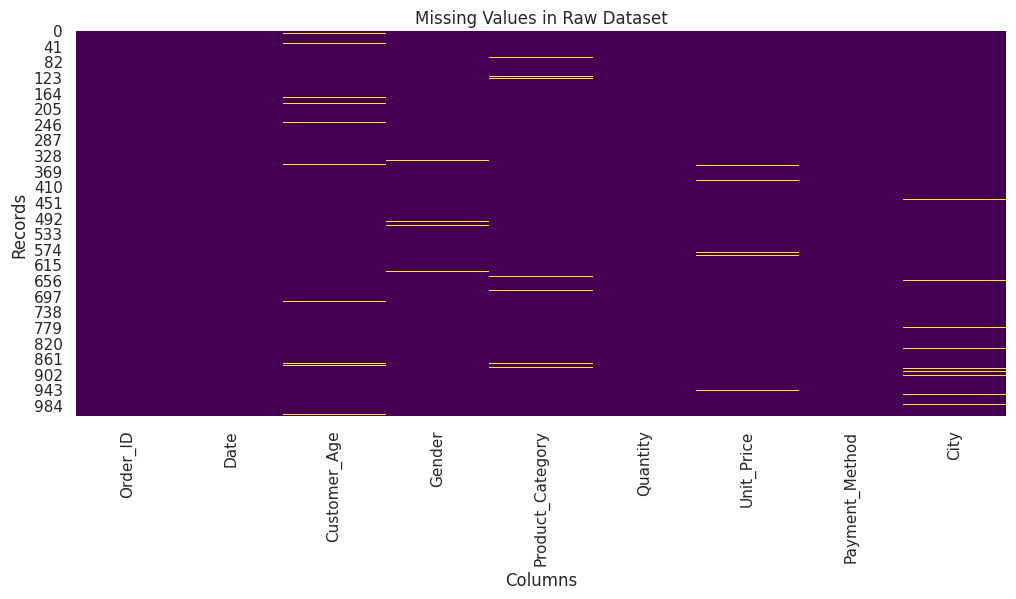

In [6]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap='viridis'
)

plt.title("Missing Values in Raw Dataset")
plt.xlabel("Columns")
plt.ylabel("Records")

plt.show()

In [7]:
numerical_columns = [
    'Customer_Age',
    'Quantity',
    'Unit_Price'
]

for column in numerical_columns:
    df[column] = df[column].fillna(
        df[column].median()
    )

print("Numerical missing values filled successfully!")

Numerical missing values filled successfully!


In [8]:
categorical_columns = [
    'Gender',
    'Product_Category',
    'Payment_Method',
    'City'
]

for column in categorical_columns:
    df[column] = df[column].fillna(
        df[column].mode()[0]
    )

print("Categorical missing values filled successfully!")

Categorical missing values filled successfully!


In [9]:
print("Remaining Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:",
      df.isnull().sum().sum())

Remaining Missing Values:
Order_ID            0
Date                0
Customer_Age        0
Gender              0
Product_Category    0
Quantity            0
Unit_Price          0
Payment_Method      0
City                0
dtype: int64

Total Missing Values: 0


In [10]:
duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 10


In [11]:
df = df.drop_duplicates()

print("Duplicate records removed successfully!")

print("Updated Dataset Shape:", df.shape)

Duplicate records removed successfully!
Updated Dataset Shape: (1000, 9)


In [12]:
print("Remaining Duplicate Records:",
      df.duplicated().sum())

display(df.head())

Remaining Duplicate Records: 0


,Order_ID,Date,Customer_Age,Gender,Product_Category,Quantity,Unit_Price,Payment_Method,City
0,1001,2025-01-01,56.0,Male,Clothing,6,760.0,Card,Bangalore
1,1002,2025-01-02,46.0,Female,Clothing,7,2735.0,Cash,Chennai
2,1003,2025-01-03,32.0,Female,Clothing,3,2429.0,Cash,Bangalore
3,1004,2025-01-04,60.0,Female,Clothing,7,4054.0,Cash,Mumbai
4,1005,2025-01-05,25.0,Male,Sports,8,2550.0,Online,Bangalore


In [13]:
outlier_columns = [
    'Customer_Age',
    'Quantity',
    'Unit_Price'
]

for column in outlier_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print(f"\n{column}")
    print("Outliers detected:", len(outliers))
    print("Lower limit:", lower_limit)
    print("Upper limit:", upper_limit)


Customer_Age
Outliers detected: 1
Lower limit: -3.0
Upper limit: 85.0

Quantity
Outliers detected: 1
Lower limit: -3.0
Upper limit: 13.0

Unit_Price
Outliers detected: 1
Lower limit: -2010.25
Upper limit: 7175.75


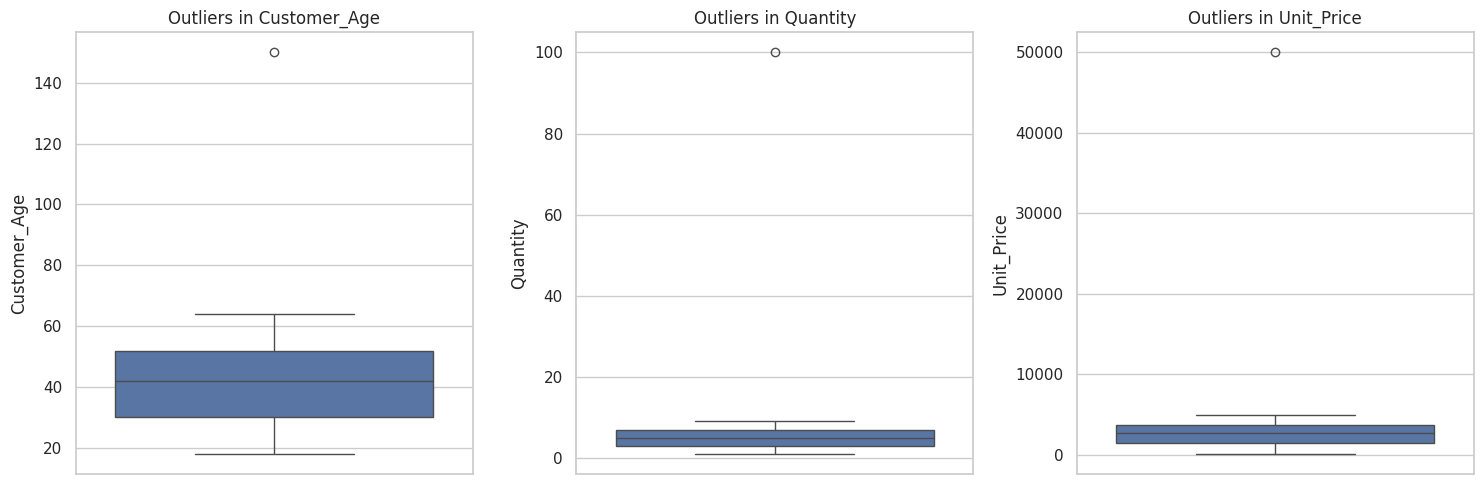

In [14]:
plt.figure(figsize=(15, 5))

for i, column in enumerate(outlier_columns, 1):

    plt.subplot(1, 3, i)

    sns.boxplot(y=df[column])

    plt.title(f"Outliers in {column}")

plt.tight_layout()
plt.show()

In [15]:
for column in outlier_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df[column] = df[column].clip(
        lower=lower_limit,
        upper=upper_limit
    )

print("Outliers handled successfully!")

Outliers handled successfully!


In [16]:
print("Before Data Transformation:")
print(df.dtypes)

Before Data Transformation:
Order_ID              int64
Date                 object
Customer_Age        float64
Gender               object
Product_Category     object
Quantity              int64
Unit_Price          float64
Payment_Method       object
City                 object
dtype: object


In [17]:
df['Date'] = pd.to_datetime(df['Date'])

print("Date column converted successfully!")

print(df['Date'].dtype)

Date column converted successfully!
datetime64[ns]


In [18]:
df['Total_Sales'] = (
    df['Quantity'] * df['Unit_Price']
)

print("Total Sales column created successfully!")

display(df[['Order_ID', 'Quantity',
            'Unit_Price', 'Total_Sales']].head(10))

Total Sales column created successfully!


,Order_ID,Quantity,Unit_Price,Total_Sales
0,1001,6,760.0,4560.0
1,1002,7,2735.0,19145.0
2,1003,3,2429.0,7287.0
3,1004,7,4054.0,28378.0
4,1005,8,2550.0,20400.0
5,1006,6,1232.0,7392.0
6,1007,9,799.0,7191.0
7,1008,6,2138.0,12828.0
8,1009,9,4747.0,42723.0
9,1010,4,4600.0,18400.0


In [19]:
df['Year'] = df['Date'].dt.year

df['Month'] = df['Date'].dt.month_name()

df['Day'] = df['Date'].dt.day

print("Date features extracted successfully!")

display(df[['Date', 'Year', 'Month', 'Day']].head())

Date features extracted successfully!


,Date,Year,Month,Day
0,2025-01-01,2025,January,1
1,2025-01-02,2025,January,2
2,2025-01-03,2025,January,3
3,2025-01-04,2025,January,4
4,2025-01-05,2025,January,5


In [20]:
df['Age_Group'] = pd.cut(
    df['Customer_Age'],
    bins=[0, 20, 30, 40, 50, 60, 100],
    labels=[
        'Below 20',
        '20-30',
        '30-40',
        '40-50',
        '50-60',
        'Above 60'
    ]
)

print("Customer age groups created!")

display(df[['Customer_Age', 'Age_Group']].head(10))

Customer age groups created!


,Customer_Age,Age_Group
0,56.0,50-60
1,46.0,40-50
2,32.0,30-40
3,60.0,50-60
4,25.0,20-30
5,42.0,40-50
6,56.0,50-60
7,36.0,30-40
8,40.0,30-40
9,28.0,20-30


In [21]:
print("========== SALES SUMMARY ==========")

print("Total Revenue: ₹",
      round(df['Total_Sales'].sum(), 2))

print("Total Orders:",
      df['Order_ID'].nunique())

print("Average Order Value: ₹",
      round(df['Total_Sales'].mean(), 2))

print("Highest Order Value: ₹",
      round(df['Total_Sales'].max(), 2))

print("Lowest Order Value: ₹",
      round(df['Total_Sales'].min(), 2))

print("Total Customers Represented:",
      len(df))

print("===================================")

========== SALES SUMMARY ==========
Total Revenue: ₹ 13006179.5
Total Orders: 1000
Average Order Value: ₹ 13006.18
Highest Order Value: ₹ 44757.0
Lowest Order Value: ₹ 118.0
Total Customers Represented: 1000


In [22]:
category_analysis = df.groupby(
    'Product_Category'
).agg(
    Total_Quantity=('Quantity', 'sum'),
    Total_Revenue=('Total_Sales', 'sum'),
    Number_of_Orders=('Order_ID', 'nunique')
).sort_values(
    by='Total_Revenue',
    ascending=False
)

display(category_analysis)

,Total_Quantity,Total_Revenue,Number_of_Orders
Product_Category,,,
Groceries,1226,3317263.0,240
Clothing,1030,2720427.0,200
Sports,1012,2631572.0,205
Electronics,924,2306844.5,187
Furniture,821,2030073.0,168


In [23]:
city_analysis = df.groupby(
    'City'
)['Total_Sales'].sum().sort_values(
    ascending=False
)

display(city_analysis)

,Total_Sales
City,
Chennai,2912483.0
Bangalore,2630019.0
Mumbai,2519061.0
Hyderabad,2476360.0
Delhi,2468256.5


In [24]:
payment_analysis = df.groupby(
    'Payment_Method'
).agg(
    Total_Orders=('Order_ID', 'nunique'),
    Total_Revenue=('Total_Sales', 'sum')
)

display(payment_analysis)

,Total_Orders,Total_Revenue
Payment_Method,,
Card,252,3232081.0
Cash,232,3198561.5
Online,265,3345859.5
UPI,251,3229677.5


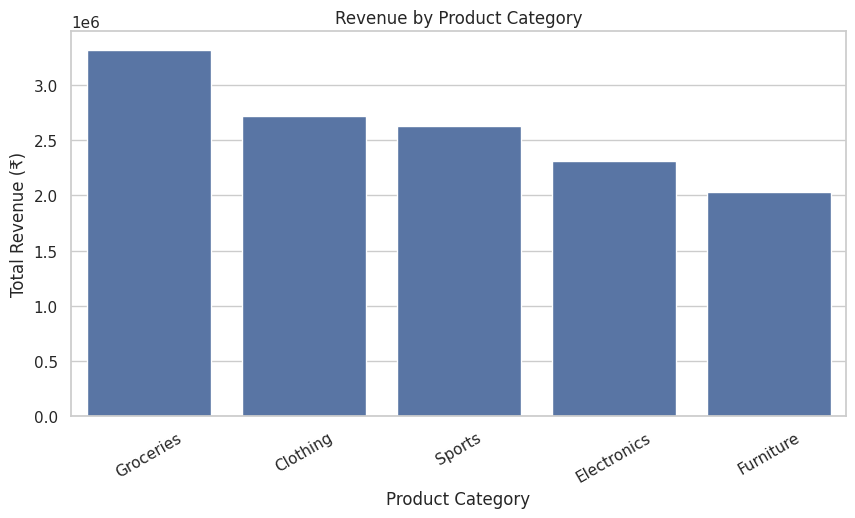

In [25]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=category_analysis.reset_index(),
    x='Product_Category',
    y='Total_Revenue'
)

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue (₹)')
plt.xticks(rotation=30)

plt.show()

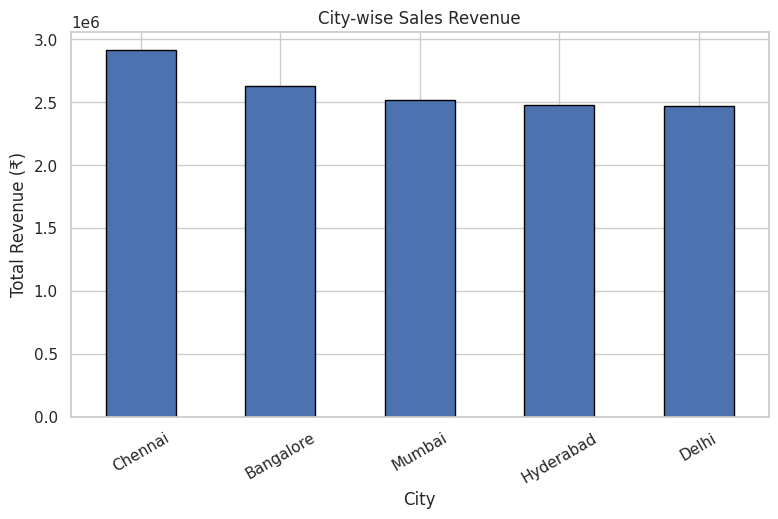

In [26]:
plt.figure(figsize=(9, 5))

city_analysis.plot(
    kind='bar',
    edgecolor='black'
)

plt.title('City-wise Sales Revenue')
plt.xlabel('City')
plt.ylabel('Total Revenue (₹)')

plt.xticks(rotation=30)
plt.show()

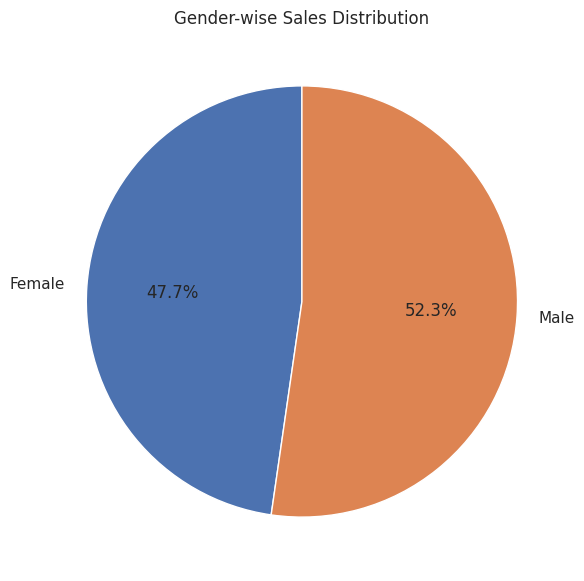

In [27]:
gender_sales = df.groupby(
    'Gender'
)['Total_Sales'].sum()

plt.figure(figsize=(7, 7))

plt.pie(
    gender_sales,
    labels=gender_sales.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Gender-wise Sales Distribution')
plt.show()

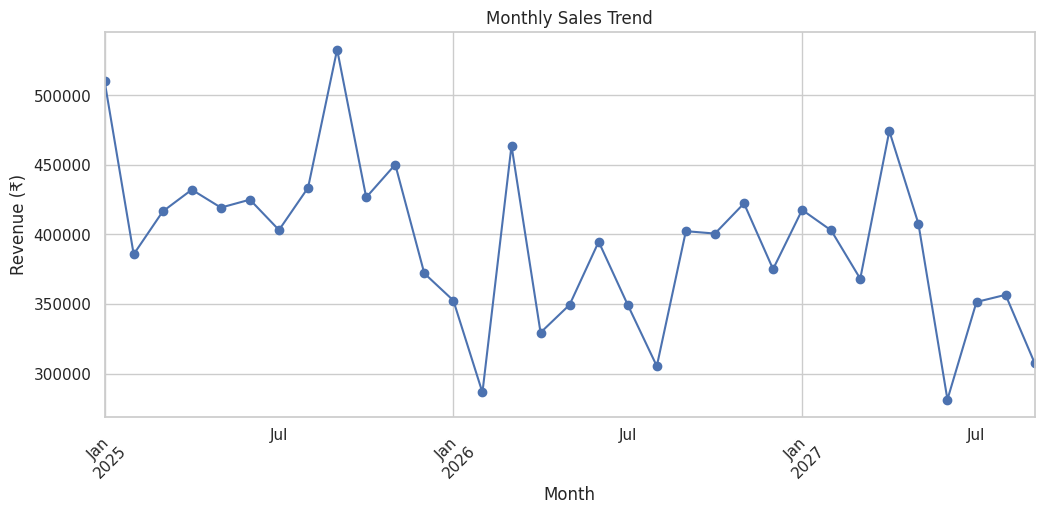

In [28]:
monthly_sales = df.groupby(
    df['Date'].dt.to_period('M')
)['Total_Sales'].sum()

plt.figure(figsize=(12, 5))

monthly_sales.plot(
    kind='line',
    marker='o'
)

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=45)

plt.grid(True)
plt.show()

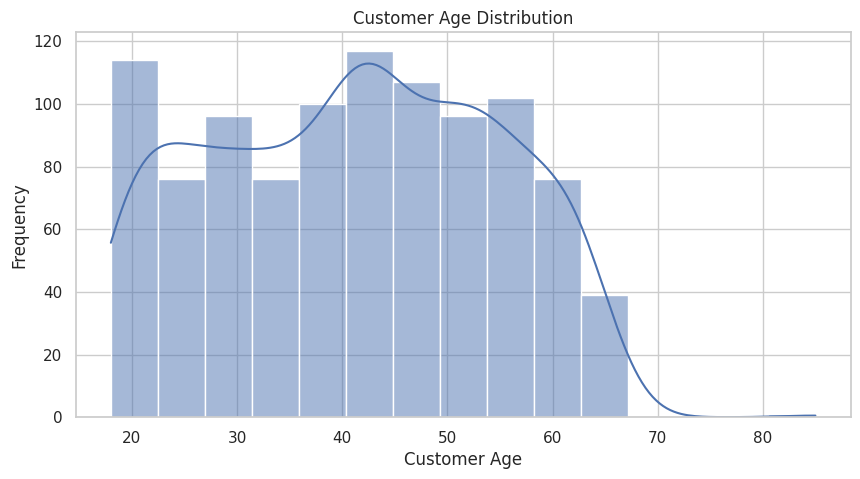

In [29]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='Customer_Age',
    bins=15,
    kde=True
)

plt.title('Customer Age Distribution')
plt.xlabel('Customer Age')
plt.ylabel('Frequency')

plt.show()

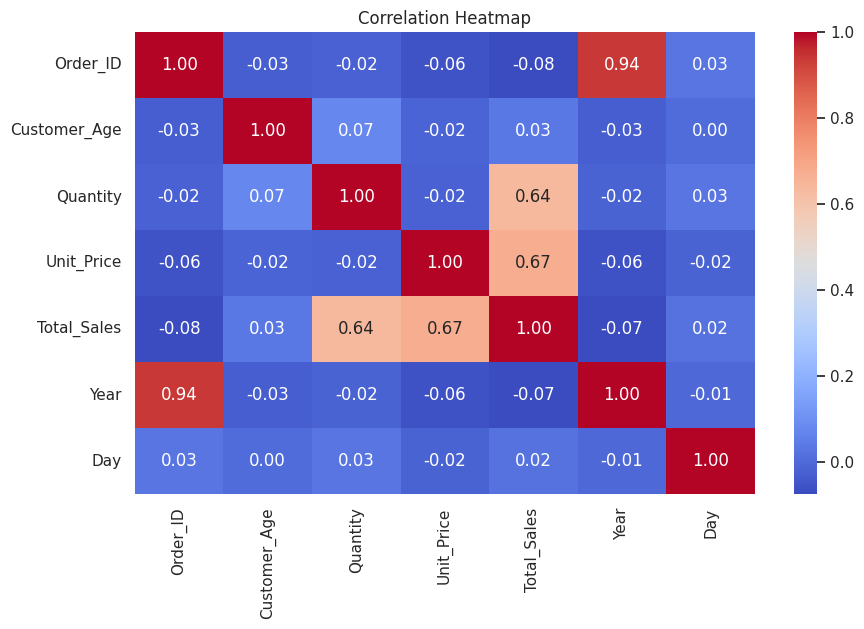

In [30]:
plt.figure(figsize=(10, 6))

correlation = df.select_dtypes(
    include='number'
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

In [31]:
print("========== FINAL DATA QUALITY REPORT ==========")

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

print("\nFinal Dataset Preview:")
display(df.head(10))

========== FINAL DATA QUALITY REPORT ==========
Dataset Shape: (1000, 14)

Missing Values:
Order_ID            0
Date                0
Customer_Age        0
Gender              0
Product_Category    0
Quantity            0
Unit_Price          0
Payment_Method      0
City                0
Total_Sales         0
Year                0
Month               0
Day                 0
Age_Group           0
dtype: int64

Total Missing Values: 0

Duplicate Records: 0

Data Types:
Order_ID                     int64
Date                datetime64[ns]
Customer_Age               float64
Gender                      object
Product_Category            object
Quantity                     int64
Unit_Price                 float64
Payment_Method              object
City                        object
Total_Sales                float64
Year                         int32
Month                       object
Day                          int32
Age_Group                 category
dtype: object

Final Dataset Preview:


,Order_ID,Date,Customer_Age,Gender,Product_Category,Quantity,Unit_Price,Payment_Method,City,Total_Sales,Year,Month,Day,Age_Group
0,1001,2025-01-01,56.0,Male,Clothing,6,760.0,Card,Bangalore,4560.0,2025,January,1,50-60
1,1002,2025-01-02,46.0,Female,Clothing,7,2735.0,Cash,Chennai,19145.0,2025,January,2,40-50
2,1003,2025-01-03,32.0,Female,Clothing,3,2429.0,Cash,Bangalore,7287.0,2025,January,3,30-40
3,1004,2025-01-04,60.0,Female,Clothing,7,4054.0,Cash,Mumbai,28378.0,2025,January,4,50-60
4,1005,2025-01-05,25.0,Male,Sports,8,2550.0,Online,Bangalore,20400.0,2025,January,5,20-30
5,1006,2025-01-06,42.0,Male,Groceries,6,1232.0,UPI,Delhi,7392.0,2025,January,6,40-50
6,1007,2025-01-07,56.0,Male,Electronics,9,799.0,Online,Bangalore,7191.0,2025,January,7,50-60
7,1008,2025-01-08,36.0,Male,Furniture,6,2138.0,Card,Mumbai,12828.0,2025,January,8,30-40
8,1009,2025-01-09,40.0,Male,Sports,9,4747.0,Card,Mumbai,42723.0,2025,January,9,30-40
9,1010,2025-01-10,28.0,Male,Electronics,4,4600.0,Card,Mumbai,18400.0,2025,January,10,20-30


In [34]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

file_name = list(uploaded.keys())[0]
raw_df = pd.read_csv(file_name)

print("Original dataset loaded successfully!")
print("Original shape:", raw_df.shape)

Saving raw_sales_dataset.csv to raw_sales_dataset (2).csv
Original dataset loaded successfully!
Original shape: (1010, 9)


In [35]:
comparison = pd.DataFrame({
    'Data Quality Metric': [
        'Total Records',
        'Missing Values',
        'Duplicate Records'
    ],
    'Original Dataset': [
        len(raw_df),
        raw_df.isnull().sum().sum(),
        raw_df.duplicated().sum()
    ],
    'Cleaned Dataset': [
        len(df),
        df.isnull().sum().sum(),
        df.duplicated().sum()
    ]
})

display(comparison)

,Data Quality Metric,Original Dataset,Cleaned Dataset
0,Total Records,1010,1000
1,Missing Values,102,0
2,Duplicate Records,10,0


In [37]:
best_category = category_analysis['Total_Revenue'].idxmax()
best_city = city_analysis.idxmax()
best_payment = payment_analysis['Total_Orders'].idxmax()

print("========== KEY BUSINESS INSIGHTS ==========")
print("Highest Revenue Product Category:", best_category)
print("Highest Revenue City:", best_city)
print("Most Used Payment Method:", best_payment)
print("Total Revenue: ₹", round(df['Total_Sales'].sum(), 2))
print("Average Order Value: ₹", round(df['Total_Sales'].mean(), 2))
print("============================================")

========== KEY BUSINESS INSIGHTS ==========
Highest Revenue Product Category: Groceries
Highest Revenue City: Chennai
Most Used Payment Method: Online
Total Revenue: ₹ 13006179.5
Average Order Value: ₹ 13006.18


In [38]:
df.to_csv('/content/cleaned_sales_dataset.csv', index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [39]:
from IPython.display import FileLink, display

display(FileLink('/content/cleaned_sales_dataset.csv'))

/content/cleaned_sales_dataset.csv

In [40]:
raw_df.to_csv('/content/raw_sales_dataset.csv', index=False)

print("Original dataset saved successfully!")

Original dataset saved successfully!


In [44]:
from google.colab import files

raw_df.to_csv('/content/raw_sales_dataset.csv', index=False)
df.to_csv('/content/cleaned_sales_dataset.csv', index=False)

files.download('/content/raw_sales_dataset.csv')
files.download('/content/cleaned_sales_dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [45]:
%%writefile /content/requirements.txt
pandas
numpy
matplotlib
seaborn

Writing /content/requirements.txt


In [46]:
from google.colab import files
files.download('/content/requirements.txt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

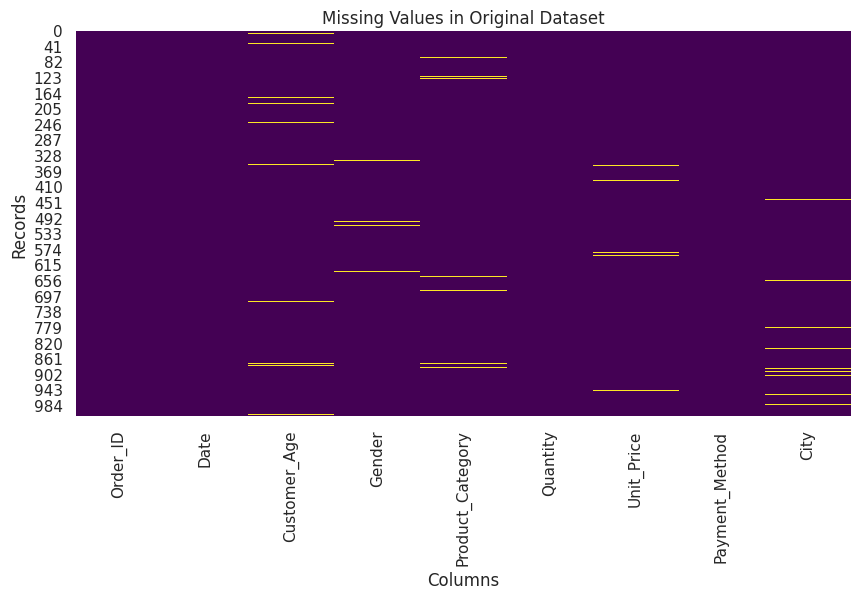

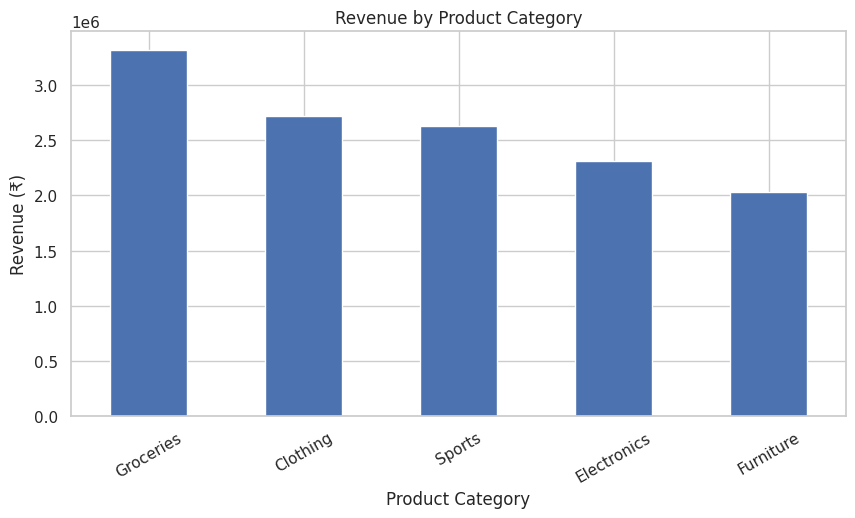

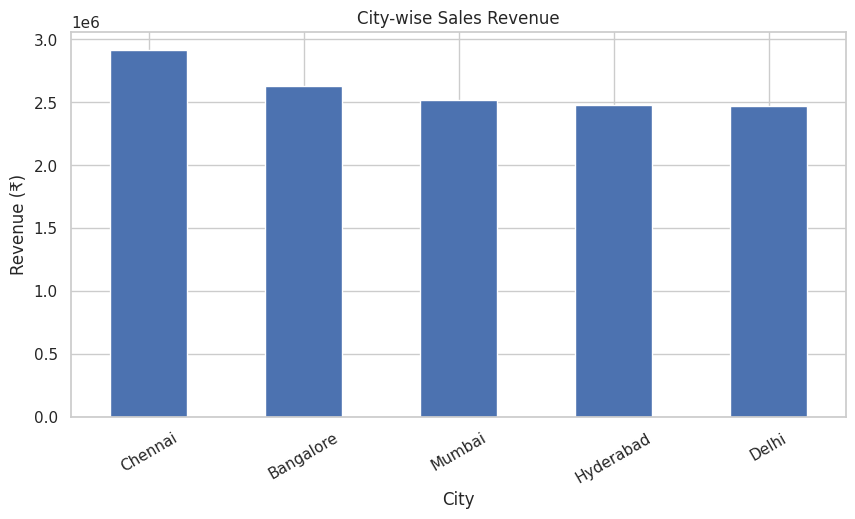

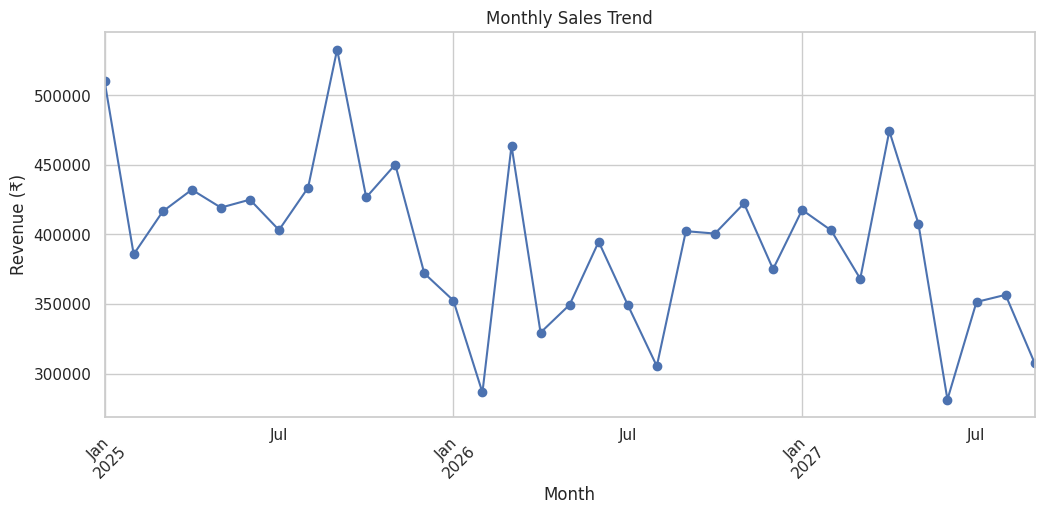

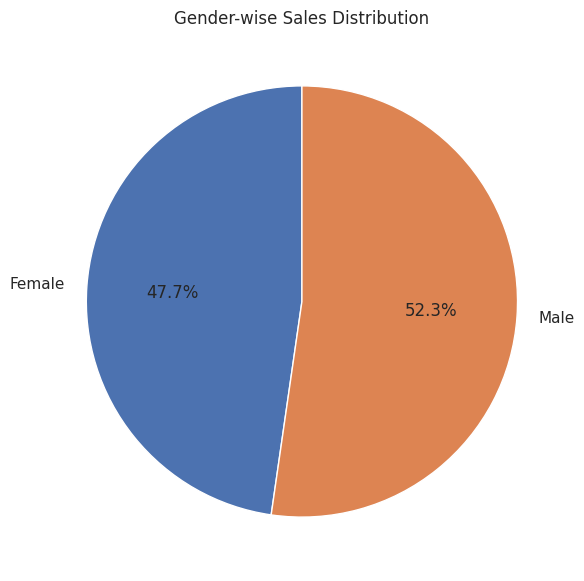

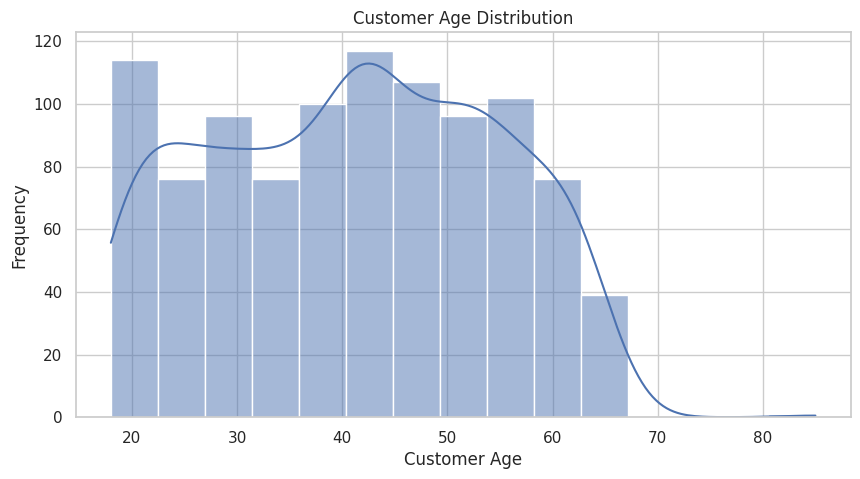

All 6 visualization images saved successfully!


In [47]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Create visualization folder
os.makedirs('/content/visualizations', exist_ok=True)

# 1. Missing Values Heatmap
plt.figure(figsize=(10, 5))
sns.heatmap(raw_df.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Values in Original Dataset')
plt.xlabel('Columns')
plt.ylabel('Records')
plt.savefig('/content/visualizations/missing_values.png', bbox_inches='tight')
plt.show()
plt.close()


# 2. Category-wise Sales
plt.figure(figsize=(10, 5))
category_sales = df.groupby('Product_Category')['Total_Sales'].sum().sort_values(ascending=False)
category_sales.plot(kind='bar')
plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=30)
plt.savefig('/content/visualizations/category_sales.png', bbox_inches='tight')
plt.show()
plt.close()


# 3. City-wise Sales
plt.figure(figsize=(10, 5))
city_sales = df.groupby('City')['Total_Sales'].sum().sort_values(ascending=False)
city_sales.plot(kind='bar')
plt.title('City-wise Sales Revenue')
plt.xlabel('City')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=30)
plt.savefig('/content/visualizations/city_sales.png', bbox_inches='tight')
plt.show()
plt.close()


# 4. Monthly Sales Trend
plt.figure(figsize=(12, 5))
monthly_sales = df.groupby(df['Date'].dt.to_period('M'))['Total_Sales'].sum()
monthly_sales.plot(kind='line', marker='o')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=45)
plt.grid(True)
plt.savefig('/content/visualizations/monthly_sales.png', bbox_inches='tight')
plt.show()
plt.close()


# 5. Gender-wise Sales
plt.figure(figsize=(7, 7))
gender_sales = df.groupby('Gender')['Total_Sales'].sum()
plt.pie(gender_sales, labels=gender_sales.index, autopct='%1.1f%%', startangle=90)
plt.title('Gender-wise Sales Distribution')
plt.savefig('/content/visualizations/gender_sales.png', bbox_inches='tight')
plt.show()
plt.close()


# 6. Customer Age Distribution
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='Customer_Age', bins=15, kde=True)
plt.title('Customer Age Distribution')
plt.xlabel('Customer Age')
plt.ylabel('Frequency')
plt.savefig('/content/visualizations/age_distribution.png', bbox_inches='tight')
plt.show()
plt.close()

print("All 6 visualization images saved successfully!")

In [48]:
from google.colab import files
import os
import time

image_files = [
    'missing_values.png',
    'category_sales.png',
    'city_sales.png',
    'monthly_sales.png',
    'gender_sales.png',
    'age_distribution.png'
]

for image_file in image_files:
    files.download('/content/visualizations/' + image_file)
    time.sleep(2)

print("All visualization downloads requested!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (3 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All visualization downloads requested!
